In [2]:
#IMPORTS
import random
from pathlib import Path
from datasets import load_dataset, Audio
import numpy as np
import pandas as pd
import torch
import torchaudio
import matplotlib.pyplot as plt
import soundfile as sf, io 
from tqdm import tqdm
import ast
from config import CHILD, CHILD_AFR_SADILAR, ADULT_NCHLT, NOISY_DIR, RESULTS_DIR
RESULTS_DIR.mkdir(exist_ok=True)


#Fixed seeds and the 16 kHz rate MMS expects
random.seed(42)
np.random.seed(42)
SAMPLE_RATE = 16000

/Users/conarj/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [2]:
#PREPARE THE MMS MODEL
#Import MMS model : 
from transformers import Wav2Vec2ForSequenceClassification, AutoFeatureExtractor

#Facebook LLM ID
lid_model_id = "facebook/mms-lid-126"

feature_extractor = AutoFeatureExtractor.from_pretrained(lid_model_id)

#wav2vec 2.0 encoder with a classification head over 126 languages
model = Wav2Vec2ForSequenceClassification.from_pretrained(lid_model_id)

device = "cpu"

#eval() switches off dropout so the predictions are repeatable
lid_model = model.to(device).eval()
print(f"Model loaded on {device}")

Model loaded on cpu


In [5]:
#LOAD AFRIKAANS ADULT DATA (NCHLT)
ADULT_MANIFEST_AFR  = ADULT_NCHLT["afr"] / "manifest.csv"
ADULT_AUDIO_DIR_AFR = ADULT_NCHLT["afr"] / "audio"
afr_utterances = []
#Read speaker as a string so IDs like '001' keep their leading zeros
afr_adult_df = pd.read_csv(ADULT_MANIFEST_AFR, dtype={"speaker":str})
#Audio is stored in one folder per speaker
afr_adult_df["path"] = afr_adult_df.apply(
    lambda r: ADULT_AUDIO_DIR_AFR / str(r["speaker"]) / r["filename"], axis=1
)
print("Amount of AFR speakers", len(afr_adult_df["speaker"].unique()))
#First five utterances of every speaker, so each speaker counts equally
afr_utterances = afr_adult_df.groupby("speaker").head(5)
print("Amount of utterances: ", len(afr_utterances))

total_h = (afr_utterances["duration_s"].sum())/3600
print(total_h)

Amount of AFR speakers 210
Amount of utterances:  1050
0.9795333333333333


In [6]:
#LOAD ENGLISH ADULT DATA (NCHLT), same steps as for Afrikaans
ADULT_MANIFEST_ENG  = ADULT_NCHLT["eng"] / "manifest.csv"
ADULT_AUDIO_DIR_ENG = ADULT_NCHLT["eng"] / "audio"
eng_utterances = []
eng_adult_df = pd.read_csv(ADULT_MANIFEST_ENG, dtype={"speaker":str})
eng_adult_df["path"] = eng_adult_df.apply(
    lambda r: ADULT_AUDIO_DIR_ENG / str(r["speaker"]) / r["filename"], axis=1
)
print("Amount of ENG speakers:", len(eng_adult_df["speaker"].unique()))
eng_utterances = eng_adult_df.groupby("speaker").head(5)
print("Amount of utterances: ", len(eng_utterances))

total_h = (eng_utterances["duration_s"].sum())/3600
print(total_h)


Amount of ENG speakers: 210
Amount of utterances:  1050
0.8625333333333333


In [7]:
#LOAD ISIXHOSA ADULT DATA (NCHLT), same steps as for Afrikaans
ADULT_MANIFEST_XHO  = ADULT_NCHLT["xho"] / "manifest.csv"
ADULT_AUDIO_DIR_XHO = ADULT_NCHLT["xho"] / "audio"
xho_utterances = []
xho_adult_df = pd.read_csv(ADULT_MANIFEST_XHO, dtype={"speaker":str})
xho_adult_df["path"] = xho_adult_df.apply(
    lambda r: ADULT_AUDIO_DIR_XHO / str(r["speaker"]) / r["filename"], axis=1
)
print("Amount of XHO speakers:", len(xho_adult_df["speaker"].unique()))
xho_utterances = xho_adult_df.groupby("speaker").head(5)
print("Amount of utterances: ", len(xho_utterances))

total_h = (xho_utterances["duration_s"].sum())/3600
print(total_h)

Amount of XHO speakers: 209
Amount of utterances:  1045
1.4414361111111111


In [8]:
#LOAD SESOTHO SA LEBOA ADULT DATA (NCHLT), same steps as for Afrikaans
ADULT_MANIFEST_NSO  = ADULT_NCHLT["nso"] / "manifest.csv"
ADULT_AUDIO_DIR_NSO = ADULT_NCHLT["nso"] / "audio"
nso_utterances = []
nso_adult_df = pd.read_csv(ADULT_MANIFEST_NSO, dtype={"speaker":str})
nso_adult_df["path"] = nso_adult_df.apply(
    lambda r: ADULT_AUDIO_DIR_NSO / str(r["speaker"]) / r["filename"], axis=1
)
print("Amount of NSO speakers:", len(nso_adult_df["speaker"].unique()))
nso_utterances = nso_adult_df.groupby("speaker").head(5)
print("Amount of utterances: ", len(nso_utterances))

total_h = (nso_utterances["duration_s"].sum())/3600
print(total_h)

Amount of NSO speakers: 210
Amount of utterances:  1050
1.1993666666666667


In [13]:
#VoxPopuli rows hold the audio as raw bytes, so decode them with soundfile
def load_audio(example):
    a = example["audio"]
    data, sr = sf.read(io.BytesIO(a["bytes"]) if a["bytes"] else a["path"],
                       dtype="float32")
    wav = torch.from_numpy(data)
    wav = wav.unsqueeze(0) if wav.ndim == 1 else wav.T   # -> (channels, samples)
    return wav, sr

In [ ]:
#LOAD DUTCH ADULT DATA (VoxPopuli test split)
#Stream it instead of downloading the whole split
vox_nl = load_dataset("facebook/voxpopuli", "nl",
                      split="test", streaming=True)
#Keep the raw bytes, load_audio decodes them
vox_nl = vox_nl.cast_column("audio", Audio(decode=False))
#Quick check that one clip decodes
first = next(iter(vox_nl)) #iter starts the stream and next pulls the first row. first is a dict
wav, sr = load_audio(first)

In [15]:
def utt_duration(audio) : 
    src = io.BytesIO(audio["bytes"]) if audio.get("bytes") else audio["path"]
    return sf.info(src).duration

In [17]:
#First 72 speakers in the stream, at most 27 utterances each
MAX_SPEAKERS = 72
PER_SPEAKER = 27

counts, rows = {}, []
for ex in vox_nl:                      
    s = ex["speaker_id"]
    #Skip new speakers once 72 have been found
    if s not in counts and len(counts) >= MAX_SPEAKERS:
        continue                       
    #Cap each speaker at 27 utterances
    if counts.get(s, 0) < PER_SPEAKER: 
        rows.append(ex)
        counts[s] = counts.get(s, 0) + 1

nl_adult_df = pd.DataFrame(rows)
print(f"{len(counts)} speakers, {len(nl_adult_df)} utterances")

nl_adult_df["duration_s"] = nl_adult_df["audio"].apply(utt_duration)

total_h = nl_adult_df["duration_s"].sum() / 3600
print(f"Total: {total_h:.2f} h over {len(nl_adult_df)} utterances "
      f"(mean {nl_adult_df['duration_s'].mean():.2f} s)")

# Optional breakdown per dialect
print((nl_adult_df["duration_s"].sum() / 3600).round(2))



72 speakers, 1029 utterances
Total: 2.41 h over 1029 utterances (mean 8.42 s)
2.41


In [ ]:
#ENGLISH ADULT DATA (OpenSLR SLR83, England accents only)
#Stream it like VoxPopuli, so the full 31 h never has to be downloaded
SLR83_CONFIGS = ["southern_female", "southern_male",
                 "midlands_female", "midlands_male",
                 "northern_female", "northern_male"]
PER_SPEAKER = 25    #Cap per speaker while streaming, keeps memory bounded
N_TOTAL = 1050      #Same size as the NCHLT sets

rows = []
for cfg in SLR83_CONFIGS:
    ds = load_dataset("ylacombe/english_dialects", cfg, split="train", streaming=True)
    #Keep the raw bytes, load_audio decodes them
    ds = ds.cast_column("audio", Audio(decode=False))
    counts = {}
    for ex in ds:
        s = ex["speaker_id"]
        if counts.get(s, 0) < PER_SPEAKER:
            #Prefix with the config so IDs from different subsets cannot clash
            ex["speaker"] = f"{cfg}_{s}"
            ex["dialect"] = cfg
            rows.append(ex)
            counts[s] = counts.get(s, 0) + 1
    print(f"{cfg}: {len(counts)} speakers")

slr_all = pd.DataFrame(rows)
#One utterance per speaker before any speaker gets a second, then cut to N_TOTAL
slr_all = slr_all.sample(frac=1, random_state=42)
slr_all["_r"] = slr_all.groupby("speaker").cumcount()
eng_slr_df = (slr_all.sort_values(["_r", "speaker"])
                     .head(N_TOTAL)
                     .drop(columns="_r")
                     .reset_index(drop=True))

print(f"{eng_slr_df['speaker'].nunique()} speakers, {len(eng_slr_df)} utterances")
print(eng_slr_df["dialect"].value_counts())

eng_slr_df["duration_s"] = eng_slr_df["audio"].apply(utt_duration)

total_h = eng_slr_df["duration_s"].sum() / 3600
print(f"Total: {total_h:.2f} h over {len(eng_slr_df)} utterances "
      f"(mean {eng_slr_df['duration_s'].mean():.2f} s)")

# Optional breakdown per dialect
print((eng_slr_df.groupby("dialect")["duration_s"].sum() / 3600).round(2))

In [3]:
#Same prediction function as in 01_mms_baseline, for files on disk
@torch.inference_mode()
def predict_language(path, topk=3): 
    wav, sr = torchaudio.load(path)
    if wav.shape[0] > 1 : 
        wav = wav.mean(0, keepdim= True)
    if sr != SAMPLE_RATE : 
        wav = torchaudio.functional.resample(wav, sr, SAMPLE_RATE)
    
    inputs = feature_extractor(wav.squeeze().numpy(), sampling_rate = SAMPLE_RATE, return_tensors = "pt").to(device)
    probs = lid_model(**inputs).logits.softmax(-1)[0]

    top = probs.topk(topk)
    return [(lid_model.config.id2label[i.item()], p.item()) for p, i in zip(top.values, top.indices)]

In [4]:
#Same as predict_language, but takes audio that is already loaded (used for VoxPopuli)
@torch.inference_mode()
def predict_language_from_audio(wav, sr, topk=3): 
    if wav.shape[0] > 1 : 
        wav = wav.mean(0, keepdim= True)
    if sr != SAMPLE_RATE : 
        wav = torchaudio.functional.resample(wav, sr, SAMPLE_RATE)
    inputs = feature_extractor(wav.squeeze().numpy(), sampling_rate = SAMPLE_RATE, return_tensors = "pt").to(device)
    probs = lid_model(**inputs).logits.softmax(-1)[0]

    top = probs.topk(topk)
    return [(lid_model.config.id2label[i.item()], p.item()) for p, i in zip(top.values, top.indices)]

In [24]:
#PREDICT AFRIKAANS AND SAVE
predictions = []
for path in tqdm(afr_utterances["path"], desc="Predicting language"):
    predictions.append(predict_language(path))

#Each column holds a (language, probability) tuple
afr_adult_results_df = pd.DataFrame(predictions, columns=["top1", "top2", "top3"])

#Total accuracy
afr_adult_results_df["correct"] = afr_adult_results_df.apply(lambda row: row["top1"][0] == "afr", axis=1)
afr_adult_results_df["path"] = afr_utterances["path"].values
afr_accuracy = afr_adult_results_df["correct"].mean()
print(f"Afrikaans Adult Accuracy: {afr_accuracy:.4f}")

#Save prediction results to CSV
afr_adult_results_df.to_csv(RESULTS_DIR / "afr_adult_results.csv", index=False) 

Predicting language:   0%|          | 0/1050 [00:00<?, ?it/s]/Users/conarj/Library/Python/3.9/lib/python/site-packages/torchaudio/_backend/utils.py:213: UserWarning: In 2.9, this function's implementation will be changed to use torchaudio.load_with_torchcodec` under the hood. Some parameters like ``normalize``, ``format``, ``buffer_size``, and ``backend`` will be ignored. We recommend that you port your code to rely directly on TorchCodec's decoder instead: https://docs.pytorch.org/torchcodec/stable/generated/torchcodec.decoders.AudioDecoder.html#torchcodec.decoders.AudioDecoder.
  warnings.warn(
Predicting language: 100%|██████████| 1050/1050 [08:28<00:00,  2.06it/s]

Afrikaans Adult Accuracy: 0.8990


In [25]:
#PREDICT ENG AND SAVE
#Same steps as for Afrikaans
predictions = []
for path in tqdm(eng_utterances["path"], desc="Predicting language"):
    predictions.append(predict_language(path))

eng_adult_results_df = pd.DataFrame(predictions, columns=["top1", "top2", "top3"])

#Total accuracy
eng_adult_results_df["correct"] = eng_adult_results_df.apply(lambda row: row["top1"][0] == "eng", axis=1)
eng_adult_results_df["path"] = eng_utterances["path"].values
eng_accuracy = eng_adult_results_df["correct"].mean()
print(f"English Adult Accuracy: {eng_accuracy:.4f}")

#Save prediction results to CSV
eng_adult_results_df.to_csv(RESULTS_DIR / "eng_adult_results.csv", index=False) 

Predicting language:   0%|          | 0/1050 [00:00<?, ?it/s]/Users/conarj/Library/Python/3.9/lib/python/site-packages/torchaudio/_backend/utils.py:213: UserWarning: In 2.9, this function's implementation will be changed to use torchaudio.load_with_torchcodec` under the hood. Some parameters like ``normalize``, ``format``, ``buffer_size``, and ``backend`` will be ignored. We recommend that you port your code to rely directly on TorchCodec's decoder instead: https://docs.pytorch.org/torchcodec/stable/generated/torchcodec.decoders.AudioDecoder.html#torchcodec.decoders.AudioDecoder.
  warnings.warn(
Predicting language: 100%|██████████| 1050/1050 [08:02<00:00,  2.18it/s]

British English Adult Accuracy: 0.2943


In [26]:
#PREDICT XHO AND SAVE
#Same steps as for Afrikaans
predictions = []
for path in tqdm(xho_utterances["path"], desc="Predicting language"):
    predictions.append(predict_language(path))

xho_adult_results_df = pd.DataFrame(predictions, columns=["top1", "top2", "top3"])

#Total accuracy
xho_adult_results_df["correct"] = xho_adult_results_df.apply(lambda row: row["top1"][0] == "xho", axis=1)
xho_adult_results_df["path"] = xho_utterances["path"].values
xho_accuracy = xho_adult_results_df["correct"].mean()
print(f"isiXhosa Adult Accuracy: {xho_accuracy:.4f}")

#Save prediction results to CSV
xho_adult_results_df.to_csv(RESULTS_DIR / "xho_adult_results.csv", index=False) 

Predicting language:   0%|          | 0/1045 [00:00<?, ?it/s]/Users/conarj/Library/Python/3.9/lib/python/site-packages/torchaudio/_backend/utils.py:213: UserWarning: In 2.9, this function's implementation will be changed to use torchaudio.load_with_torchcodec` under the hood. Some parameters like ``normalize``, ``format``, ``buffer_size``, and ``backend`` will be ignored. We recommend that you port your code to rely directly on TorchCodec's decoder instead: https://docs.pytorch.org/torchcodec/stable/generated/torchcodec.decoders.AudioDecoder.html#torchcodec.decoders.AudioDecoder.
  warnings.warn(
Predicting language: 100%|██████████| 1045/1045 [12:28<00:00,  1.40it/s]

isiXhosa Adult Accuracy: 0.6057


In [27]:
#PREDICT NSO AND SAVE
#Same steps as for Afrikaans
predictions = []
for path in tqdm(nso_utterances["path"], desc="Predicting language"):
    predictions.append(predict_language(path))

nso_adult_results_df = pd.DataFrame(predictions, columns=["top1", "top2", "top3"])

#Total accuracy
nso_adult_results_df["correct"] = nso_adult_results_df.apply(lambda row: row["top1"][0] == "nso", axis=1)
nso_adult_results_df["path"] = nso_utterances["path"].values
nso_accuracy = nso_adult_results_df["correct"].mean()
print(f"Sesotho sa Leboa Adult Accuracy: {nso_accuracy:.4f}")

#Save prediction results to CSV
nso_adult_results_df.to_csv(RESULTS_DIR / "nso_adult_results.csv", index=False) 

Predicting language:   0%|          | 0/1050 [00:00<?, ?it/s]/Users/conarj/Library/Python/3.9/lib/python/site-packages/torchaudio/_backend/utils.py:213: UserWarning: In 2.9, this function's implementation will be changed to use torchaudio.load_with_torchcodec` under the hood. Some parameters like ``normalize``, ``format``, ``buffer_size``, and ``backend`` will be ignored. We recommend that you port your code to rely directly on TorchCodec's decoder instead: https://docs.pytorch.org/torchcodec/stable/generated/torchcodec.decoders.AudioDecoder.html#torchcodec.decoders.AudioDecoder.
  warnings.warn(
Predicting language: 100%|██████████| 1050/1050 [10:58<00:00,  1.59it/s] 

Sesotho sa Leboa Adult Accuracy: 0.6371


In [28]:
#PREDICT NLD AND SAVE
predictions = []
#VoxPopuli audio is already in memory, so use predict_language_from_audio
for i in tqdm(range(len(nl_adult_df)), desc="Predicting language"):
    wav, sr = load_audio(nl_adult_df.iloc[i])
    predictions.append(predict_language_from_audio(wav, sr))

nl_results_df = pd.DataFrame(predictions, columns=["top1", "top2", "top3"])

#Total accuracy
nl_results_df["correct"] = nl_results_df.apply(lambda row: row["top1"][0] == "nld", axis=1)
nl_accuracy = nl_results_df["correct"].mean()
print(f"Dutch Adult Accuracy: {nl_accuracy:.4f}")

#Save prediction results to CSV
nl_results_df.to_csv(RESULTS_DIR / "nl_adult_results.csv", index=False) 

Predicting language: 100%|██████████| 1029/1029 [21:16<00:00,  1.24s/it]

Dutch Adult Accuracy: 0.9854


In [10]:
# Okabe-Ito colorblind-safe palette
OKABE = {"blue":"#0072B2", "orange":"#E69F00", "green":"#009E73",
         "vermillion":"#D55E00", "grey":"#999999"}

#Needs the top1_lang and top1_acc columns made in the cells below
def unpack(results_df):
    """Add flat columns for the top-1 code and its probability."""
    df = results_df.copy()
    df["pred"] = df["top1_lang"]
    df["conf"] = df["top1_acc"].astype(float)
    return df

#Bar chart of everything MMS predicted for one language, correct language in blue
def plot_prediction_distribution(results_df, true_lang, group="adult", ax=None):
    df = unpack(results_df)
    counts = df["pred"].value_counts()
    n = len(df)

    ax = ax or plt.subplots(figsize=(7, max(2.5, 0.4*len(counts))))[1]
    order = counts.index[::-1]                    # largest at top
    colors = [OKABE["blue"] if c == true_lang else OKABE["grey"] for c in order]
    ax.barh(range(len(order)), counts[order].values, color=colors)

    ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
    for i, c in enumerate(order):                 # direct value labels: count + %
        v = counts[c]
        ax.text(v + n*0.005, i, f"{v}  ({v/n:.1%})", va="center", fontsize=9)

    acc = (df["pred"] == true_lang).mean()
    ax.set_title(f"MMS predictions on {true_lang} {group} speech  "
                 f"(top-1 accuracy = {acc:.1%}, N={n})", fontsize=11)
    ax.set_xlabel("utterances"); ax.set_xlim(0, counts.max()*1.18)
    for s in ("top","right","left"): ax.spines[s].set_visible(False)
    ax.tick_params(left=False)
    return ax

Afrikaans Adult Accuracy: 0.8990


<Axes: title={'center': 'MMS predictions on afr adult speech  (top-1 accuracy = 89.9%, N=1050)'}, xlabel='utterances'>

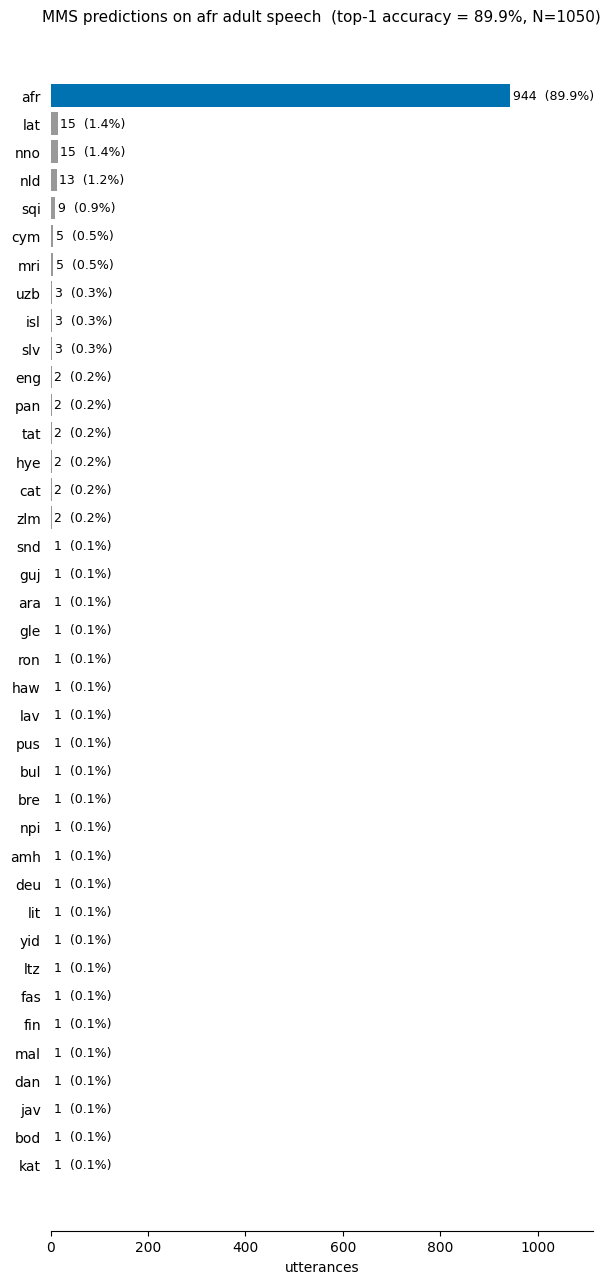

In [30]:
#AFRIKAANS ADULT RESULTS
#Split each (language, probability) tuple into two columns
for k in ["top1", "top2", "top3"]:
    col = afr_adult_results_df[k]
    #Tuples become strings when they are read back from CSV
    if isinstance(col.iloc[0], str):          
        col = col.apply(ast.literal_eval)
    afr_adult_results_df[[f"{k}_lang", f"{k}_acc"]] = pd.DataFrame(
        col.tolist(), index=afr_adult_results_df.index
    )
afr_adult_results_df["correct"] = afr_adult_results_df.apply(lambda row: row["top1_lang"] == "afr", axis=1)
afr_accuracy = afr_adult_results_df["correct"].mean()
print(f"Afrikaans Adult Accuracy: {afr_accuracy:.4f}")
plot_prediction_distribution(afr_adult_results_df, "afr")

Afrikaans Adult Accuracy: 0.2943


<Axes: title={'center': 'MMS predictions on eng adult speech  (top-1 accuracy = 29.4%, N=1050)'}, xlabel='utterances'>

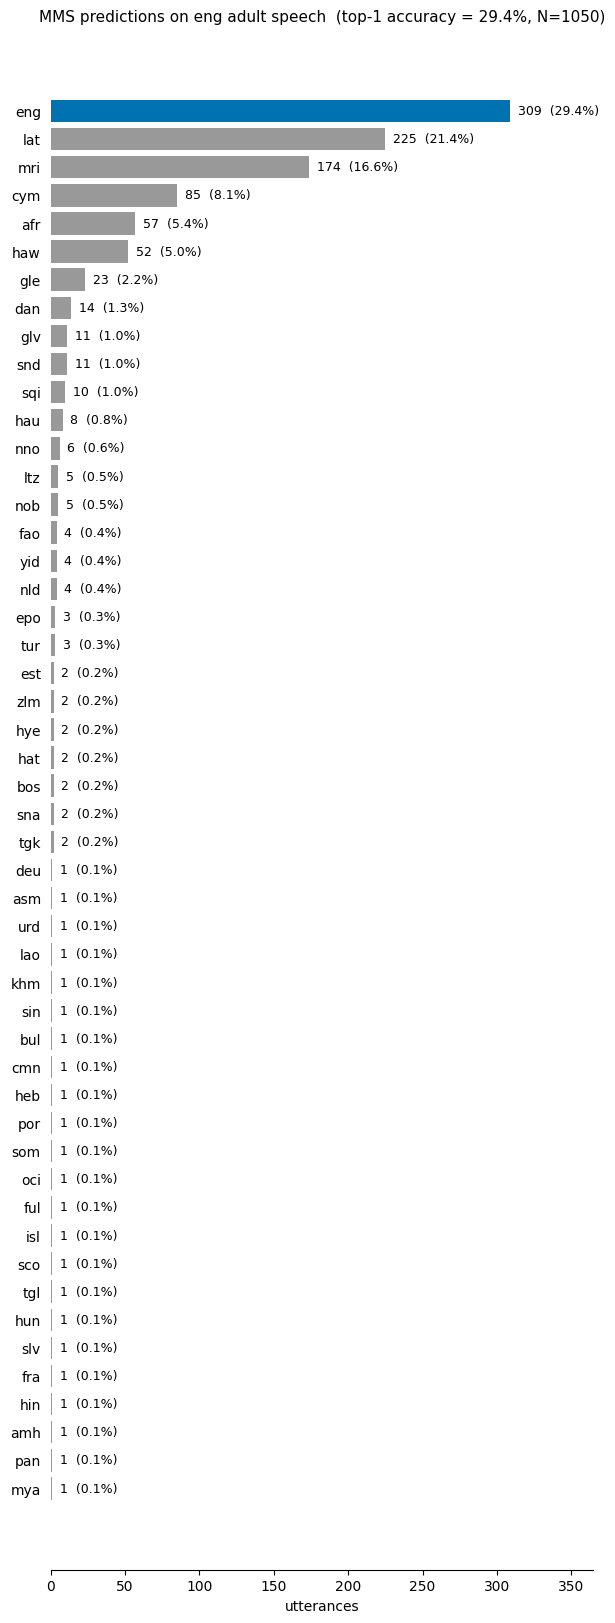

In [31]:
#ENGLISH ADULT RESULTS, same steps as for Afrikaans
for k in ["top1", "top2", "top3"]:
    col = eng_adult_results_df[k]
    if isinstance(col.iloc[0], str):          # only parse if it was read back from CSV
        col = col.apply(ast.literal_eval)
    eng_adult_results_df[[f"{k}_lang", f"{k}_acc"]] = pd.DataFrame(
        col.tolist(), index=eng_adult_results_df.index
    )
eng_adult_results_df["correct"] = eng_adult_results_df.apply(lambda row: row["top1_lang"] == "eng", axis=1)
eng_accuracy = eng_adult_results_df["correct"].mean()
print(f"English Adult Accuracy: {eng_accuracy:.4f}")
plot_prediction_distribution(eng_adult_results_df, "eng")

Afrikaans Adult Accuracy: 0.6057


<Axes: title={'center': 'MMS predictions on xho adult speech  (top-1 accuracy = 60.6%, N=1045)'}, xlabel='utterances'>

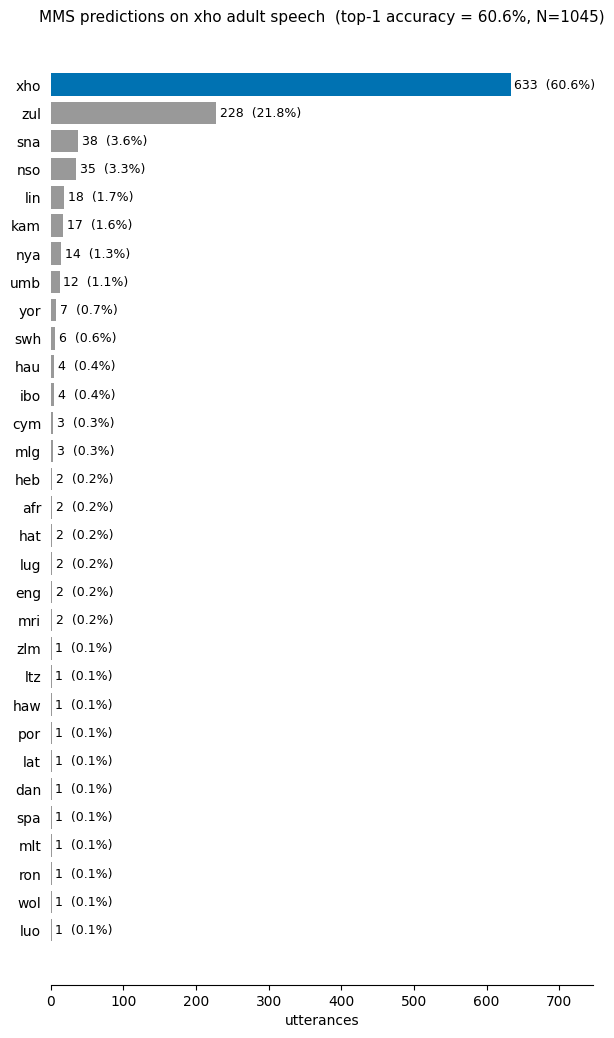

In [32]:
#ISIXHOSA ADULT RESULTS, same steps as for Afrikaans
for k in ["top1", "top2", "top3"]:
    col = xho_adult_results_df[k]
    if isinstance(col.iloc[0], str):          # only parse if it was read back from CSV
        col = col.apply(ast.literal_eval)
    xho_adult_results_df[[f"{k}_lang", f"{k}_acc"]] = pd.DataFrame(
        col.tolist(), index=xho_adult_results_df.index
    )
xho_adult_results_df["correct"] = xho_adult_results_df.apply(lambda row: row["top1_lang"] == "xho", axis=1)
xho_accuracy = xho_adult_results_df["correct"].mean()
print(f"isiXhosa Adult Accuracy: {xho_accuracy:.4f}")
plot_prediction_distribution(xho_adult_results_df, "xho")

Sesotho sa Leboa Adult Accuracy: 0.6371


<Axes: title={'center': 'MMS predictions on nso adult speech  (top-1 accuracy = 63.7%, N=1050)'}, xlabel='utterances'>

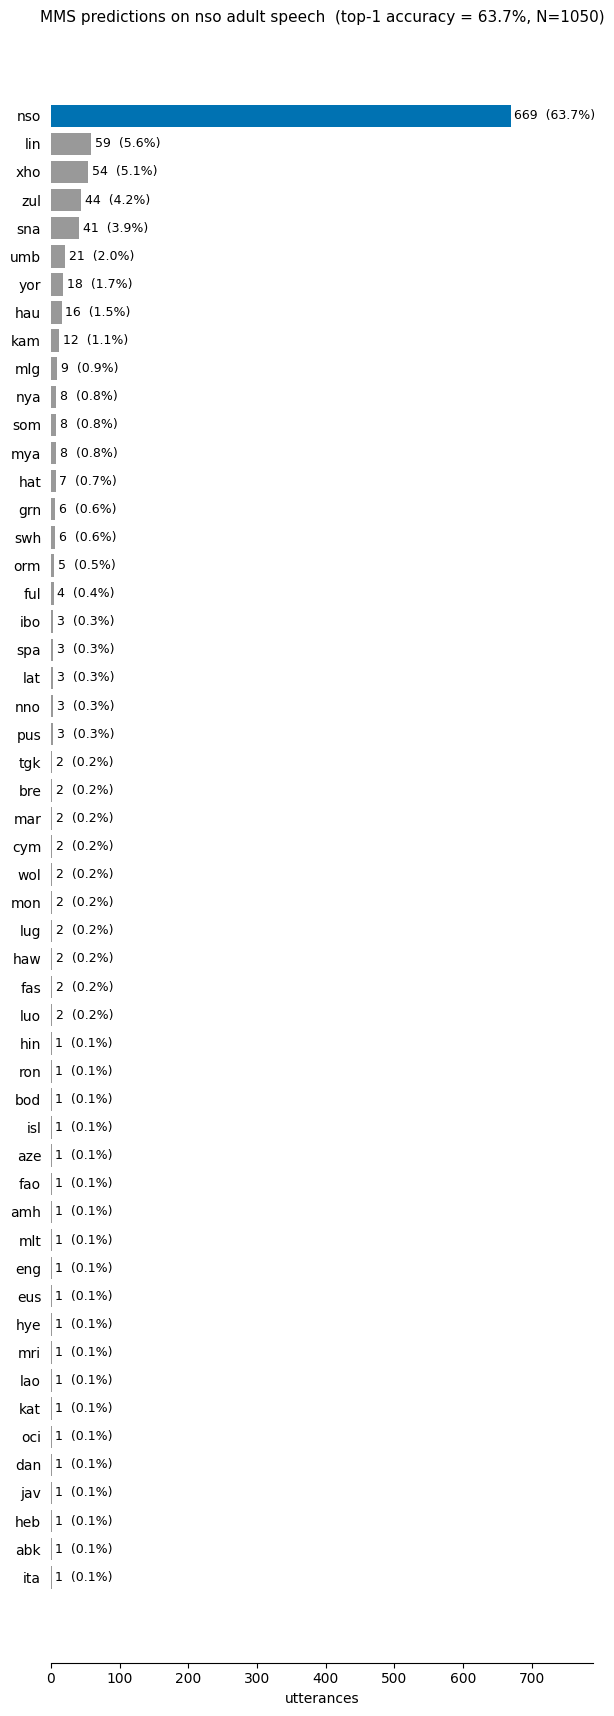

In [33]:
#SESOTHO SA LEBOA ADULT RESULTS, same steps as for Afrikaans
for k in ["top1", "top2", "top3"]:
    col = nso_adult_results_df[k]
    if isinstance(col.iloc[0], str):          # only parse if it was read back from CSV
        col = col.apply(ast.literal_eval)
    nso_adult_results_df[[f"{k}_lang", f"{k}_acc"]] = pd.DataFrame(
        col.tolist(), index=nso_adult_results_df.index
    )
nso_adult_results_df["correct"] = nso_adult_results_df.apply(lambda row: row["top1_lang"] == "nso", axis=1)
nso_accuracy = nso_adult_results_df["correct"].mean()
print(f"Sesotho sa Leboa Adult Accuracy: {nso_accuracy:.4f}")
plot_prediction_distribution(nso_adult_results_df, "nso")

Dutchc Adult Accuracy: 0.9854


<Axes: title={'center': 'MMS predictions on nld adult speech  (top-1 accuracy = 98.5%, N=1029)'}, xlabel='utterances'>

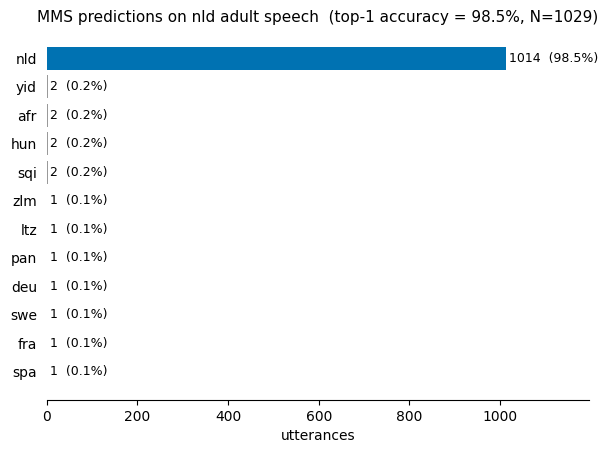

In [34]:
#DUTCH ADULT RESULTS, same steps as for Afrikaans
for k in ["top1", "top2", "top3"]:
    col = nl_results_df[k]
    if isinstance(col.iloc[0], str):          # only parse if it was read back from CSV
        col = col.apply(ast.literal_eval)
    nl_results_df[[f"{k}_lang", f"{k}_acc"]] = pd.DataFrame(
        col.tolist(), index=nl_results_df.index
    )
nl_results_df["correct"] = nl_results_df.apply(lambda row: row["top1_lang"] == "nld", axis=1)
nl_accuracy = nl_results_df["correct"].mean()
print(f"Dutch Adult Accuracy: {nl_accuracy:.4f}")
plot_prediction_distribution(nl_results_df, "nld")

In [9]:
#PREDICT ENGLISH (SLR83) AND SAVE
#Audio is already in memory, so use predict_language_from_audio (it resamples 48 kHz -> 16 kHz)
predictions = []
for i in tqdm(range(len(eng_slr_df)), desc="Predicting language"):
    wav, sr = load_audio(eng_slr_df.iloc[i])
    predictions.append(predict_language_from_audio(wav, sr))

eng_slr_results_df = pd.DataFrame(predictions, columns=["top1", "top2", "top3"])
#Split each (language, probability) tuple into two columns for the plot
for k in ["top1", "top2", "top3"]:
    eng_slr_results_df[[f"{k}_lang", f"{k}_acc"]] = pd.DataFrame(
        eng_slr_results_df[k].tolist(), index=eng_slr_results_df.index)

eng_slr_results_df["speaker"] = eng_slr_df["speaker"].values
eng_slr_results_df["dialect"] = eng_slr_df["dialect"].values
eng_slr_results_df["correct"] = eng_slr_results_df["top1_lang"] == "eng"

print(f"English (SLR83) Adult Accuracy: {eng_slr_results_df['correct'].mean():.4f}")
print(eng_slr_results_df.groupby("dialect")["correct"].mean().round(4))

eng_slr_results_df.to_csv(RESULTS_DIR / "eng_slr83_adult_results.csv", index=False)
plot_prediction_distribution(eng_slr_results_df, "eng")

Predicting language: 100%|██████████| 1050/1050 [15:32<00:00,  1.13it/s] 


English (SLR83) Adult Accuracy: 0.9914
dialect
midlands_female    1.0000
midlands_male      1.0000
northern_female    0.9846
northern_male      0.9780
southern_female    0.9945
southern_male      0.9947
Name: correct, dtype: float64


NameError: name 'plot_prediction_distribution' is not defined

<Axes: title={'center': 'MMS predictions on eng adult speech  (top-1 accuracy = 99.1%, N=1050)'}, xlabel='utterances'>

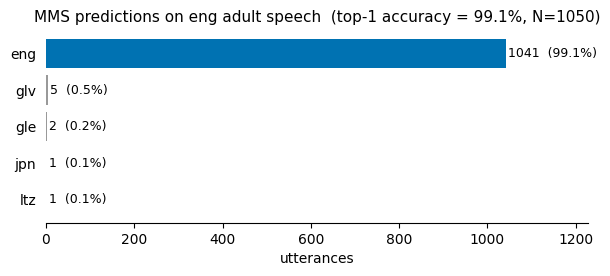

In [11]:
plot_prediction_distribution(eng_slr_results_df, "eng")